# Chapter 4: Lines and Points

Companion notebook for *Master Data Visualization: A Hands-On Beginner's Guide with Python, Matplotlib, Seaborn & Plotly*.

Run the cells from top to bottom (**Kernel → Restart Kernel and Run All Cells**). The data files this chapter uses are in the same folder as this notebook.

## 4.1 Line Charts

In [1]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.style.use('book.mplstyle')

In [2]:
sales = pd.read_csv('daily_sales.csv', parse_dates=['date'])
sales.head()

,date,revenue,orders,target
0,2025-01-06,1740,29,1900
1,2025-01-07,1560,24,1900
2,2025-01-08,1870,32,1900
3,2025-01-09,1850,31,1900
4,2025-01-10,1700,30,1900


### `ax.plot()`

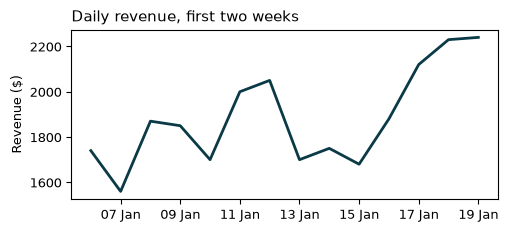

In [3]:
first_weeks = sales.head(14)

fig, ax = plt.subplots(figsize=(5.5, 2.2))
ax.plot(first_weeks['date'], first_weeks['revenue'])
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
ax.set_title('Daily revenue, first two weeks')
ax.set_ylabel('Revenue ($)')
plt.show()

### Markers

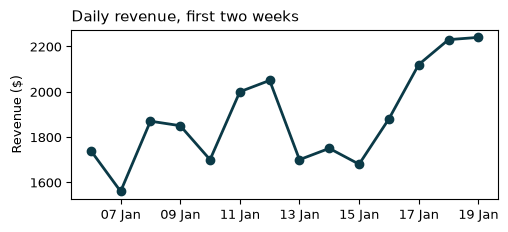

In [4]:
fig, ax = plt.subplots(figsize=(5.5, 2.2))
ax.plot(first_weeks['date'], first_weeks['revenue'], marker='o')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
ax.set_title('Daily revenue, first two weeks')
ax.set_ylabel('Revenue ($)')
plt.show()

### Line style, color and width

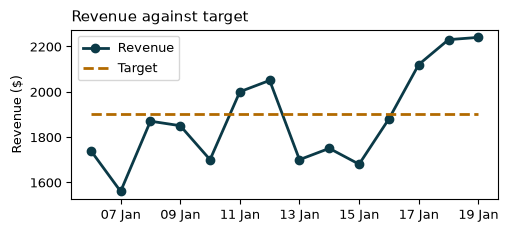

In [5]:
fig, ax = plt.subplots(figsize=(5.5, 2.2))
ax.plot(first_weeks['date'], first_weeks['revenue'],
        marker='o', label='Revenue')
ax.plot(first_weeks['date'], first_weeks['target'],
        linestyle='--', label='Target')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
ax.set_title('Revenue against target')
ax.set_ylabel('Revenue ($)')
ax.legend()
plt.show()

## 4.2 Dates on the Axis

In [6]:
raw = pd.read_csv('daily_sales.csv')
raw.dtypes

date         str
revenue    int64
orders     int64
target     int64
dtype: object

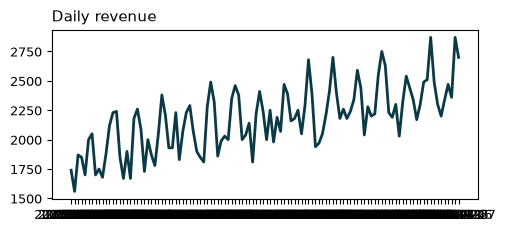

In [7]:
fig, ax = plt.subplots(figsize=(5.5, 2.2))
ax.plot(raw['date'], raw['revenue'])
ax.set_title('Daily revenue')
plt.show()

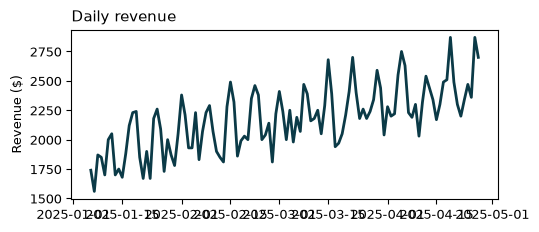

In [8]:
fig, ax = plt.subplots(figsize=(5.5, 2.2))
ax.plot(sales['date'], sales['revenue'])
ax.set_title('Daily revenue')
ax.set_ylabel('Revenue ($)')
plt.show()

### `mdates.DateFormatter()`

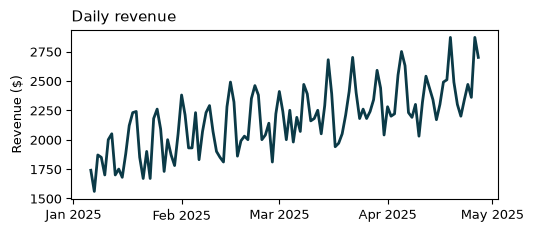

In [9]:
fig, ax = plt.subplots(figsize=(5.5, 2.2))
ax.plot(sales['date'], sales['revenue'])
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.set_title('Daily revenue')
ax.set_ylabel('Revenue ($)')
plt.show()

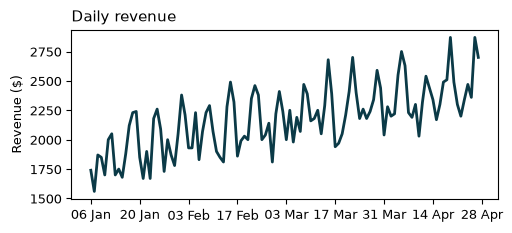

In [10]:
fig, ax = plt.subplots(figsize=(5.5, 2.2))
ax.plot(sales['date'], sales['revenue'])
ax.xaxis.set_major_locator(
    mdates.WeekdayLocator(byweekday=mdates.MO, interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
ax.set_title('Daily revenue')
ax.set_ylabel('Revenue ($)')
plt.show()

## 4.3 Smoothing a Noisy Line

In [11]:
daily = sales.set_index('date')
daily.head(3)

,revenue,orders,target
date,,,
2025-01-06,1740,29,1900
2025-01-07,1560,24,1900
2025-01-08,1870,32,1900


### `df.resample()`

In [12]:
weekly = daily['revenue'].resample('W').sum()
weekly.head()

date
2025-01-12    12770
2025-01-19    13600
2025-01-26    13620
2025-02-02    14020
2025-02-09    14510
Freq: W-SUN, Name: revenue, dtype: int64

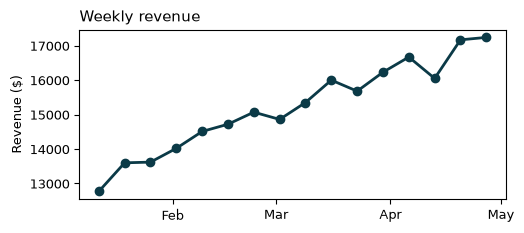

In [13]:
fig, ax = plt.subplots(figsize=(5.5, 2.2))
ax.plot(weekly.index, weekly, marker='o')
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
ax.set_title('Weekly revenue')
ax.set_ylabel('Revenue ($)')
plt.show()

### `rolling().mean()`

In [14]:
daily['avg_7d'] = daily['revenue'].rolling(7).mean()
daily[['revenue', 'avg_7d']].head(8)

,revenue,avg_7d
date,,
2025-01-06,1740,NaN
2025-01-07,1560,NaN
2025-01-08,1870,NaN
2025-01-09,1850,NaN
2025-01-10,1700,NaN
2025-01-11,2000,NaN
2025-01-12,2050,1824.285714
2025-01-13,1700,1818.571429


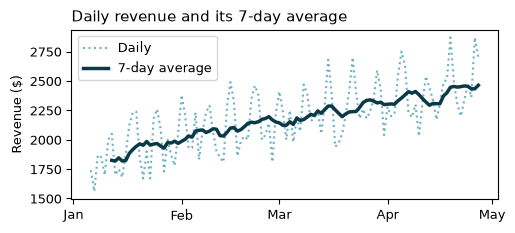

In [15]:
fig, ax = plt.subplots(figsize=(5.5, 2.2))
ax.plot(daily.index, daily['revenue'], color='#6fb3c2',
        linestyle=':', linewidth=1.5, label='Daily')
ax.plot(daily.index, daily['avg_7d'], color='#0b3a47',
        linewidth=2.5, label='7-day average')
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
ax.set_title('Daily revenue and its 7-day average')
ax.set_ylabel('Revenue ($)')
ax.legend()
plt.show()

## 4.4 Shaded Ranges

### `ax.fill_between()`

In [16]:
spread = daily['revenue'].resample('W').agg(['min', 'mean', 'max'])
spread.head(4)

,min,mean,max
date,,,
2025-01-12,1560,1824.285714,2050
2025-01-19,1680,1942.857143,2240
2025-01-26,1670,1945.714286,2260
2025-02-02,1730,2002.857143,2380


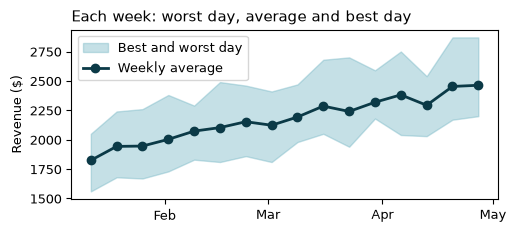

In [17]:
fig, ax = plt.subplots(figsize=(5.5, 2.2))
ax.fill_between(spread.index, spread['min'], spread['max'],
                color='#6fb3c2', alpha=0.4,
                label='Best and worst day')
ax.plot(spread.index, spread['mean'], marker='o',
        label='Weekly average')
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
ax.set_title('Each week: worst day, average and best day')
ax.set_ylabel('Revenue ($)')
ax.legend(loc='upper left')
plt.show()

### Shading where one line beats another

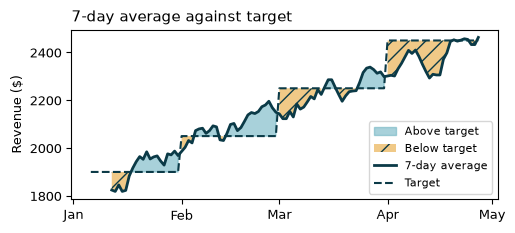

In [18]:
avg = daily['avg_7d']
target = daily['target']

fig, ax = plt.subplots(figsize=(5.5, 2.2))
ax.fill_between(daily.index, avg, target, where=avg >= target,
                color='#6fb3c2', alpha=0.6, label='Above target')
ax.fill_between(daily.index, avg, target, where=avg < target,
                facecolor='#f0c987', edgecolor='#0b3a47',
                hatch='//', linewidth=0, label='Below target')
ax.plot(daily.index, avg, color='#0b3a47', label='7-day average')
ax.plot(daily.index, target, color='#0b3a47',
        linestyle='--', linewidth=1.5, label='Target')
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
ax.set_title('7-day average against target')
ax.set_ylabel('Revenue ($)')
ax.legend(loc='lower right', fontsize=8)
plt.show()

## 4.5 Scatter Plots

In [19]:
products = pd.read_csv('products.csv')
products['revenue'] = products['price'] * products['units']
products.head()

,product,price,units,rating,revenue
0,Webcam,59,236,4.1,13924
1,Keyboard,45,412,4.5,18540
2,Monitor,189,88,4.3,16632
3,Headphones,79,229,3.8,18091
4,USB Cable,9,1180,3.6,10620


### `ax.scatter()`

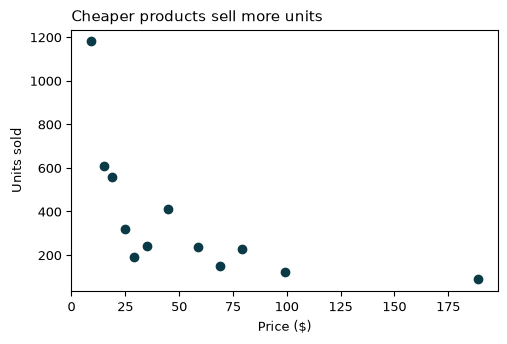

In [20]:
fig, ax = plt.subplots()
ax.scatter(products['price'], products['units'])
ax.set_title('Cheaper products sell more units')
ax.set_xlabel('Price ($)')
ax.set_ylabel('Units sold')
plt.show()

### Size with `s=`

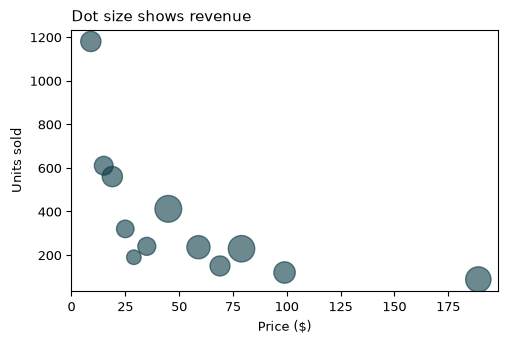

In [21]:
fig, ax = plt.subplots()
ax.scatter(products['price'], products['units'],
           s=products['revenue'] / 50, alpha=0.6)
ax.set_title('Dot size shows revenue')
ax.set_xlabel('Price ($)')
ax.set_ylabel('Units sold')
plt.show()

### Color with `c=` and `fig.colorbar()`

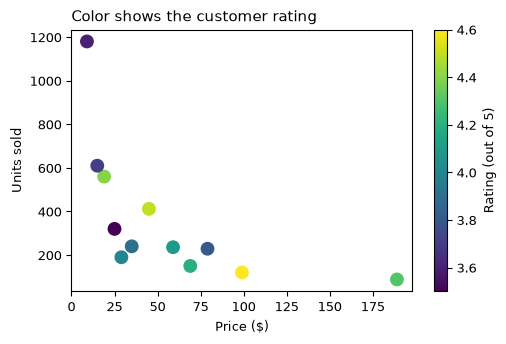

In [22]:
fig, ax = plt.subplots()
points = ax.scatter(products['price'], products['units'],
                    c=products['rating'], cmap='viridis', s=80)
fig.colorbar(points, ax=ax, label='Rating (out of 5)')
ax.set_title('Color shows the customer rating')
ax.set_xlabel('Price ($)')
ax.set_ylabel('Units sold')
plt.show()